In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import neo

%matplotlib inline
mpl.rcParams['font.size']    = 8.0
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['font.family']  = 'Arial'

In [2]:
project_root = os.getcwd()

os.chdir('./dataFolder/load_intan_rhd_format/')

if 'load_intan_rhd_format' in sys.modules:
    del sys.modules['load_intan_rhd_format']
if 'intanutil' in sys.modules:
    del sys.modules['intanutil']
from load_intan_rhd_format import read_data
os.chdir(project_root)


print('read_data loaded OK:', read_data)
print('cwd:', os.getcwd())

read_data loaded OK: <function read_data at 0x1081e0fe0>
cwd: /Users/meghnaanand/Desktop/PiliferAnalysis


In [19]:
rhd_path = './dataFolder/1_RHD_Files/m31_wn2.rhd'
out_path = './dataFolder/Figures/HatCheck/'
print(f'Loading {rhd_path} ...')
result = read_data(rhd_path)
print('\nKeys in result dict:')
print(list(result.keys()))

Loading ./dataFolderST/1_RHD_Files/m31_wn2.rhd ...

Reading Intan Technologies RHD Data File, Version 1.5

Found 16 amplifier channels.
Found 0 auxiliary input channels.
Found 0 supply voltage channels.
Found 1 board ADC channel.
Found 1 board digital input channel.
Found 0 board digital output channels.
Found 0 temperature sensors channels.

File contains 361.664 seconds of data.  Amplifiers were sampled at 30.00 kS/s.

Allocating memory for data...
Reading data from file...
10% done...
20% done...
30% done...
40% done...
50% done...
60% done...
70% done...
80% done...
90% done...
Parsing data...
Done!  Elapsed time: 10.2 seconds

Keys in result dict:
['spike_triggers', 'amplifier_channels', 'notes', 'frequency_parameters', 'board_adc_channels', 'board_dig_in_channels', 't_amplifier', 'amplifier_data', 't_board_adc', 'board_adc_data', 't_dig', 'board_dig_in_data']


In [21]:
moth_to_channel = {
    'm31_wn2': 'A-028',}

In [22]:
moth     = 'm31_wn2'
unit_id  = 3                                    # the unit- whichever i want 
Fs       = 30000
window_ms = (-1.5, 2.0)                                            # -1ms before spike to +2ms after- can edit this
pre_samples  = int(abs(window_ms[0]) * Fs / 1000)                  # 30 samples before
post_samples = int(window_ms[1] * Fs / 1000)                       # 60 samples after
total_samples = pre_samples + post_samples                         # 90 samples = 3 ms


# spike_files = {
#     'm11_wn2': './dataFolder/2_Spikesorted_Files/m11_wn2_15.txt',
#     'm23_wn2': './dataFolder/2_Spikesorted_Files/m23_wn2_01.txt',
#     'm29_wn2': './dataFolder/2_Spikesorted_Files/m29_wn2_12.txt',
#     'm30_wn1': './dataFolder/2_Spikesorted_Files/m30_wn1_07.txt',
#     'm31_wn2': './dataFolder/2_Spikesorted_Files/m31_wn2_14.txt',}

spike_files = {
    'm31_wn2': './dataFolder/2_Spikesorted_Files/m31_wn2_028_ST.txt',}

T = pd.read_csv(spike_files[moth], delimiter=r'\s+')
print(f'total spikes in file: {len(T)}, units present: {sorted(T["Unit"].unique())}')

# takes only spikes of unit ID- (can make a run through all)
spike_times_s = T.loc[T['Unit'] == unit_id, 'Timestamp'].values
print(f'unit {unit_id}: {len(spike_times_s)} spikes')

# find the right voltage channel
target = moth_to_channel[moth]
ch_idx = next(i for i, ch in enumerate(result['amplifier_channels']) 
              if ch['native_channel_name'] == target)
print(f'using channel {target} (Python index {ch_idx})')

voltage = result['amplifier_data'][ch_idx]
print(f'voltage trace length: {len(voltage)} samples = {len(voltage)/Fs:.1f} s')

# convert spike times to sample indices, extract snippets
spike_idx = (spike_times_s * Fs).astype(int)
snippets = []
for s in spike_idx:
    start = s - pre_samples
    stop  = s + post_samples
    if start < 0 or stop > len(voltage):
        continue                                                   # skip spikes too close to recording edges
    snippets.append(voltage[start:stop])
snippets = np.array(snippets)
print(f'extracted {len(snippets)} waveform snippets, shape: {snippets.shape}')

total spikes in file: 15082, units present: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
unit 3: 528 spikes
using channel A-028 (Python index 12)
voltage trace length: 10849920 samples = 361.7 s
extracted 528 waveform snippets, shape: (528, 105)


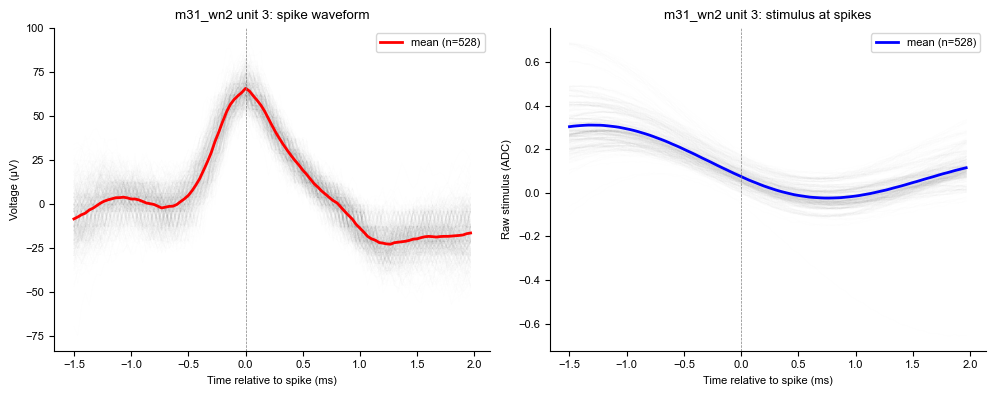

In [23]:
# ---- load the raw stimulus (ADC channel) for this moth ----
stim = pd.read_csv('./dataFolder/3_ReadRHD_files/' + moth + '_RawStimulusData.csv')['stimulus'].values

# ---- cut a stimulus snippet around each spike, same window as the spike waveforms ----
stim_snips = []                                   # will hold one stimulus snippet per spike
for s in spike_idx:                               # spike_idx = spike sample numbers (from SpikeCheck cell 4)
    start, stop = s - pre_samples, s + post_samples   # window edges (pre/post_samples from cell 4)
    if start < 0 or stop > len(stim):             # skip spikes too near the recording ends
        continue
    stim_snips.append(stim[start:stop])           # grab the stimulus in that window
stim_snips = np.array(stim_snips)                 # stack into a 2D array (n_spikes x window)

t_ms = np.arange(-pre_samples, post_samples) / Fs * 1000   # shared x-axis in ms, spike at 0

# ---- one figure, two panels side by side ----
fig, (a0, a1) = plt.subplots(1, 2, figsize=(10, 4))

# LEFT panel: spike waveforms (neural voltage)
for snip in snippets:                             # snippets = neural spike waveforms (from SpikeCheck cell 4)
    a0.plot(t_ms, snip, color='gray', alpha=0.01, linewidth=0.5)   # each spike, very faint
a0.plot(t_ms, snippets.mean(axis=0), 'r', linewidth=2, label=f'mean (n={len(snippets)})')  # mean, red
a0.axvline(0, color='grey', ls='--', lw=0.5)      # dashed line at spike time
a0.set_xlabel('Time relative to spike (ms)'); a0.set_ylabel('Voltage (µV)')
a0.set_title(f'{moth} unit {unit_id}: spike waveform'); a0.legend(fontsize=8)

# RIGHT panel: stimulus at those same spike times
for snip in stim_snips:                           # each stimulus snippet, very faint
    a1.plot(t_ms, snip, color='gray', alpha=0.01, linewidth=0.5)
a1.plot(t_ms, stim_snips.mean(axis=0), 'b', linewidth=2, label=f'mean (n={len(stim_snips)})')  # mean, blue
a1.axvline(0, color='grey', ls='--', lw=0.5)
a1.set_xlabel('Time relative to spike (ms)'); a1.set_ylabel('Raw stimulus (ADC)')
a1.set_title(f'{moth} unit {unit_id}: stimulus at spikes'); a1.legend(fontsize=8)

for a in (a0, a1):                                # tidy both panels
    a.spines['top'].set_visible(False); a.spines['right'].set_visible(False)

plt.tight_layout()
out_fig = './dataFolderST/Figures/HatCheck/'        # save folder (HatCheck, not SpikeWaveformCheck)
os.makedirs(out_fig, exist_ok=True)               # make it if it doesn't exist
fig.savefig(out_fig + f'{moth}_unit_{unit_id}_spikevsstim.pdf', bbox_inches='tight')   # save the figure
plt.show()                                        # display it

In [59]:
# example_spike_s = spike_times_s[100]
# print(f'spike #5000 at t={example_spike_s:.4f} s')

# window_ms_wide = 50
# start = int((example_spike_s - window_ms_wide/1000) * Fs)
# stop  = int((example_spike_s + window_ms_wide/1000) * Fs)
# t_wide  = (np.arange(start, stop) / Fs - example_spike_s) * 1000
# v_wide  = voltage[start:stop]

# fig, ax = plt.subplots(figsize=(10, 3))
# ax.plot(t_wide, v_wide, color='black', linewidth=0.5)
# ax.axvline(0, color='red', linestyle='--', linewidth=0.8, label='spike timestamp')
# ax.set_xlabel('Time relative to spike (ms)')
# ax.set_ylabel('Voltage (µV)')
# ax.set_title(f'{moth} unit {unit_id}: ±{window_ms_wide} ms around one spike')
# ax.legend(fontsize=8)
# ax.spines['top'].set_visible(False)
# ax.spines['right'].set_visible(False)
# plt.tight_layout()
# plt.show()

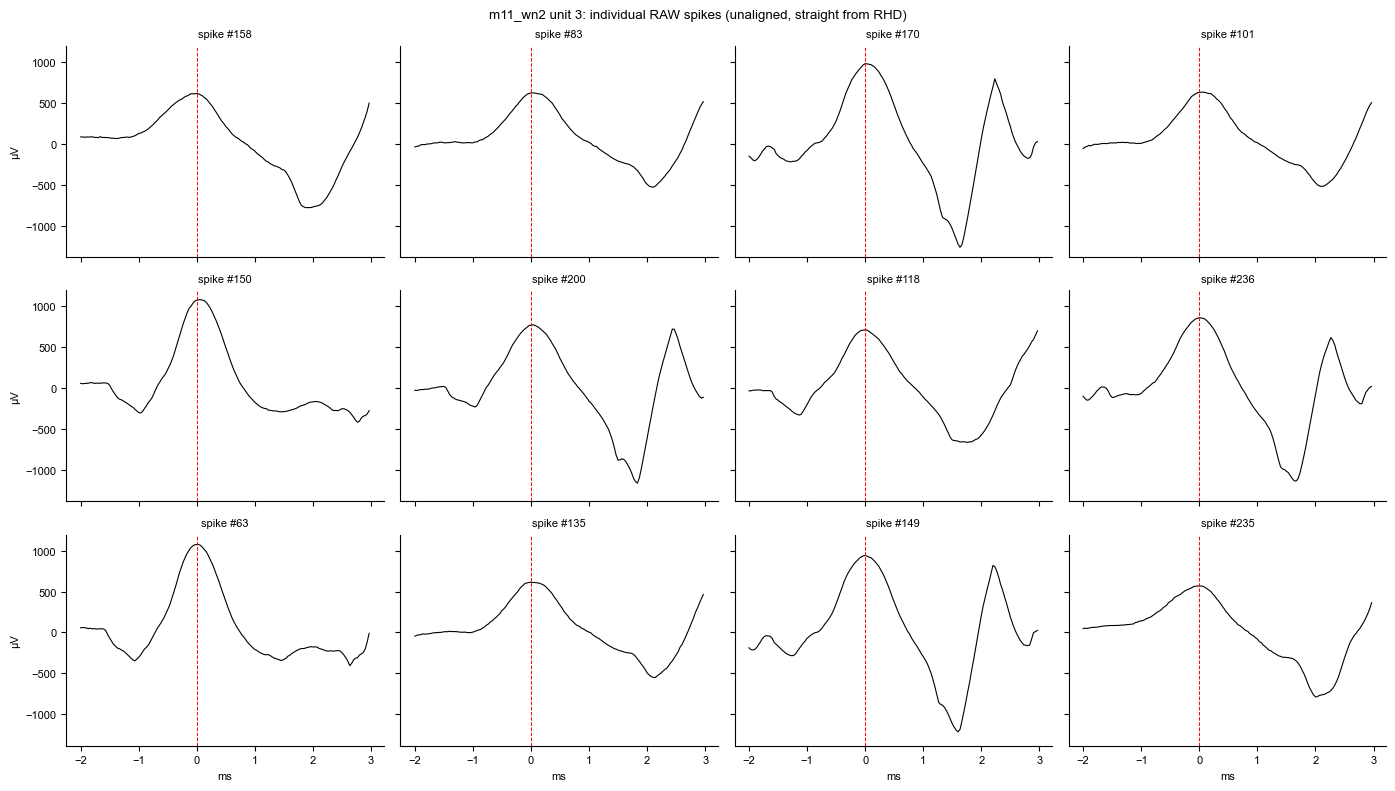

In [60]:
# pull a handful of INDIVIDUAL raw spikes straight from the RHD amplifier trace,
# no averaging, no re-alignment — to see if the "hat" is in the raw voltage
# or only appears after Plexon's peak-alignment.

pre_w, post_w = int(2e-3*Fs), int(3e-3*Fs)      # wider: 2 ms before, 3 ms after
t_w = np.arange(-pre_w, post_w) / Fs * 1000

np.random.seed(0)
pick = np.random.choice(len(spike_idx), 12, replace=False)   # 12 random spikes

fig, axes = plt.subplots(3, 4, figsize=(14, 8), sharex=True, sharey=True)
for ax, k in zip(axes.ravel(), pick):
    s = spike_idx[k]
    seg = voltage[s-pre_w : s+post_w]
    if len(seg) != pre_w+post_w:
        continue
    ax.plot(t_w, seg, 'k', linewidth=0.8)
    ax.axvline(0, color='r', ls='--', lw=0.7)
    ax.set_title(f'spike #{k}', fontsize=8)
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
for ax in axes[-1]: ax.set_xlabel('ms')
for ax in axes[:,0]: ax.set_ylabel('µV')
fig.suptitle(f'{moth} unit {unit_id}: individual RAW spikes (unaligned, straight from RHD)')
plt.tight_layout()
out_fig = './dataFolder/Figures/HatCheck/'        # save folder (HatCheck, not SpikeWaveformCheck)
os.makedirs(out_fig, exist_ok=True)               # make it if it doesn't exist
fig.savefig(out_fig + f'{moth}_unit_{unit_id}_randomspikeshapes.pdf', bbox_inches='tight')   # save the figure
plt.show()                                        # display it

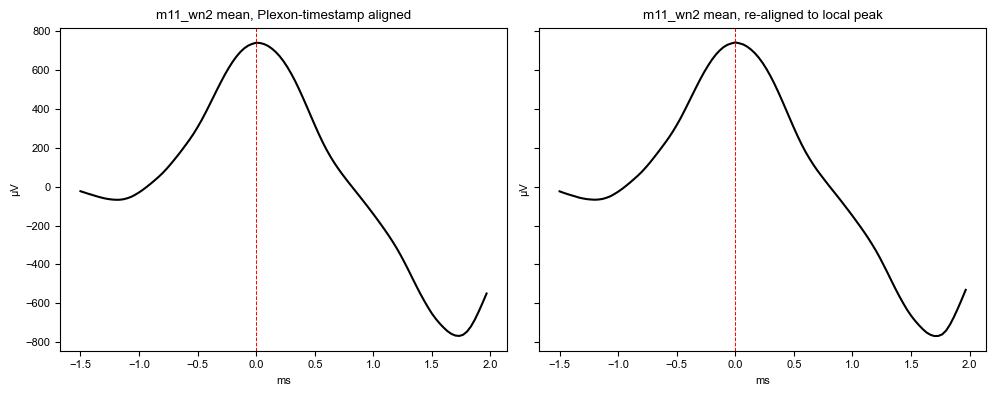

In [61]:
pre_w, post_w = int(1.5e-3*Fs), int(2e-3*Fs)
t = np.arange(-pre_w, post_w) / Fs * 1000

aligned_ts = np.array([voltage[s-pre_w:s+post_w] for s in spike_idx
                       if 0 <= s-pre_w and s+post_w <= len(voltage)])

w = int(0.5e-3*Fs)
realigned = []
for s in spike_idx:
    lo, hi = s-w, s+w
    if lo<0 or hi>len(voltage): continue
    peak = lo + np.argmax(voltage[lo:hi])
    seg = voltage[peak-pre_w:peak+post_w]
    if len(seg)==pre_w+post_w: realigned.append(seg)
realigned = np.array(realigned)

fig,(a,b)=plt.subplots(1,2,figsize=(10,4),sharey=True)
a.plot(t, aligned_ts.mean(0),'k'); a.set_title(f'{moth} mean, Plexon-timestamp aligned')
b.plot(t, realigned.mean(0),'k'); b.set_title(f'{moth} mean, re-aligned to local peak')
for ax in (a,b): ax.axvline(0,color='r',ls='--',lw=0.7); ax.set_xlabel('ms'); ax.set_ylabel('µV')
plt.tight_layout(); plt.show()

In [62]:
# remainder check: are the spike timestamps on the sample grid, or interpolated (off-grid)?
si  = spike_times_s * Fs                    # spike times (s) -> sample number (float)
rem = si - np.round(si)                     # how far each sits from the nearest whole sample

print(f'{moth} unit {unit_id}')
print(f'  fraction off-grid   : {np.mean(np.abs(rem) > 1e-6):.4f}')   # 0 = all on grid
print(f'  max off-grid distance: {np.abs(rem).max():.4f} samples')     # ~0 = grid-locked
print(f'  example remainders  : {rem[:10]}')

m11_wn2 unit 3
  fraction off-grid   : 0.0000
  max off-grid distance: 0.0000 samples
  example remainders  : [ 1.01863407e-10  0.00000000e+00  0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  1.16415322e-10  9.89530236e-10
  0.00000000e+00 -9.89530236e-10]


In [11]:
for ch in result['amplifier_channels']:
    print(ch['native_channel_name'])

A-000
A-001
A-002
A-003
A-004
A-005
A-006
A-007
A-008
A-009
A-010
A-011
A-012
A-013
A-014
A-015
